# Areal Data Issues: MAUP, Spatial Misalignment, and Ecological Fallacy
### Theoretical Foundations, Empirical Simulations, and Methodological Solutions in R

---

### The Perils of Aggregated Spatial Data

Analyzing data aggregated across discrete geographic boundaries (such as census tracts, counties, postal codes, or administrative health districts) introduces profound methodological challenges that do not exist in classical non-spatial statistics. When continuous processes are filtered through artificial administrative partitions, statistical associations can be altered, inverted, or completely manufactured.

This notebook provides an in-depth treatment of the three fundamental structural hazards of areal spatial data science:
1. **The Modifiable Areal Unit Problem (MAUP)** (Openshaw, 1984): The sensitivity of statistical results to the scale and zoning configuration of spatial boundaries.
2. **The Ecological Fallacy and Robinson's Paradox** (Robinson, 1950): The invalid deduction of individual-level relationships from group-level aggregates.
3. **The Spatial Misalignment / Change of Support Problem (COSP)** (Banerjee et al., 2004): Modeling variables observed across incompatible spatial resolutions or non-overlapping geometries.

---

### 1. The Modifiable Areal Unit Problem (MAUP)

First formalized by Stan Openshaw (1984), the **MAUP** establishes that statistical conclusions derived from areal data are conditional on the specific geometric partitioning used for aggregation. The MAUP operates through two distinct, interrelated mechanisms:

#### A. The Scale Effect
The **scale effect** occurs when the spatial aggregation level changes while holding the study extent constant:
* **Variance Suppression**: As spatial units are aggregated into larger regions ($n$ decreases), individual within-zone variance is averaged out. Regional variance declines proportionally to $1/m$, where $m$ is the mean number of subunits per zone.
* **Correlation Inflation**: Because local noise is averaged out, correlation coefficients ($r$) and coefficients of determination ($R^2$) systematically inflate as scale becomes coarser. An association that is weak ($r \approx 0.25$) at the city-block level can easily exceed $r \approx 0.85$ when aggregated to county or state levels.
* **Regression Slope Instability**: Regression slopes can change magnitude and even reverse sign across aggregation hierarchies.

#### B. The Zoning Effect
The **zoning effect** occurs when the number of zones is held constant, but the boundary configurations are altered:
* Arbitrary boundary drawing (e.g., political gerrymandering or differing administrative delimitations) reshuffles individuals among adjacent zones.
* Even with identical underlying populations and identical zone counts, changing the shape or orientation of boundaries can alter correlation coefficients from negative to positive.

---

### 2. The Ecological Fallacy & Ecological Bias

The **Ecological Fallacy** (Robinson, 1950; Selvin, 1958) is the logical error of inferring individual-level causal mechanisms from aggregate, population-level statistical associations.

#### Robinson's Classic Paradox (1950)
In a landmark 1950 paper, William S. Robinson analyzed literacy rates and foreign-born populations across the United States:
* At the **state level** ($n = 48$), the correlation between the proportion of foreign-born residents and the illiteracy rate was **$r = -0.53$** (suggesting foreign-born populations were *more* literate).
* At the **individual level** ($n = 97\text{ million}$), the true correlation was **$r = +0.11$** (reflecting lower English literacy among recent immigrants due to language barriers).
* **The Mechanism**: Immigrants disproportionately settled in wealthy, highly urbanized northeastern states that had well-funded public educational systems, creating a spurious positive state-level association between immigrant concentration and overall literacy.

#### Ecological Bias Components
As formalized by Gotway and Young (2002), ecological bias consists of:
1. **Aggregation Bias**: Arises purely from grouping heterogeneous individuals into homogeneous summaries.
2. **Specification Bias**: Confounding induced by the uneven spatial distribution of background risk factors across administrative partitions.

---

### 3. Spatial Misalignment & Change of Support (COSP)

In practical environmental and epidemiological research, spatial data rarely share a unified geometry:
* **Point-to-Area Misalignment**: Air quality monitoring stations record continuous pollution measurements at exact coordinates $(s_1, \dots, s_K)$, while health registries record cancer mortality counts across polygonal counties $(A_1, \dots, A_n)$.
* **Area-to-Area Misalignment**: Exposure data are aggregated by watershed boundaries or satellite grid cells ($5\text{km} \times 5\text{km}$), while outcome data follow census tracts.

#### Advanced Modern Solutions
1. **Bayesian Melding**:
   Assumes a single underlying continuous Gaussian Random Field $S(s)$ that drives both point observations and areal aggregates:
   $$Y(A_i) = \frac{1}{|A_i|} \int_{A_i} S(s) \, ds$$
   Inference is implemented using the Stochastic Partial Differential Equation (SPDE) approach and INLA.
2. **Bayesian Downscaling**:
   Integrates point- and area-level data via spatially varying coefficient models to predict exposure surfaces at fine, policy-relevant spatial resolutions.


In [1]:
librarian::shelf(sf, tidyverse, patchwork)

options(
  ark.plot.width = 10, ark.plot.height = 4.0,
  repr.plot.width = 10, repr.plot.height = 4.0
)


In [2]:
set.seed(42)
grid_dim <- 16

df_micro <- expand.grid(
  x = 1:grid_dim,
  y = 1:grid_dim
)

df_micro <- df_micro |>
  mutate(
    X = 0.5 * x + 0.3 * y + rnorm(n(), mean = 0, sd = 1.2),
    Y = 0.4 * X + 0.3 * x - 0.2 * y + rnorm(n(), mean = 0, sd = 1.5)
  )

cor_micro <- cor(df_micro$X, df_micro$Y)
cat("Micro-scale correlation (n = 256):", round(cor_micro, 3), "\n")


Micro-scale correlation (n = 256): 0.644 


In [3]:
# 8x8 grid (64 zones)
df_scale8 <- df_micro |>
  mutate(
    zone_x = ceiling(x / 2),
    zone_y = ceiling(y / 2)
  ) |>
  group_by(zone_x, zone_y) |>
  summarise(X = mean(X), Y = mean(Y), .groups = "drop")

cor_scale8 <- cor(df_scale8$X, df_scale8$Y)

# 4x4 grid (16 zones)
df_scale4 <- df_micro |>
  mutate(
    zone_x = ceiling(x / 4),
    zone_y = ceiling(y / 4)
  ) |>
  group_by(zone_x, zone_y) |>
  summarise(X = mean(X), Y = mean(Y), .groups = "drop")

cor_scale4 <- cor(df_scale4$X, df_scale4$Y)

cat("Scale Effect Progression:\n")
cat("  Micro scale (256 zones): r =", round(cor_micro, 3), "\n")
cat("  Medium scale (64 zones): r =", round(cor_scale8, 3), "\n")
cat("  Coarse scale (16 zones): r =", round(cor_scale4, 3), "\n")


Scale Effect Progression:
  Micro scale (256 zones): r = 0.644 
  Medium scale (64 zones): r = 0.734 
  Coarse scale (16 zones): r = 0.747 


In [4]:
p_scale1 <- ggplot(df_micro, aes(x = X, y = Y)) +
  geom_point(color = "#0284c7", alpha = 0.55, size = 1.4) +
  geom_smooth(method = "lm", color = "#0f172a", linewidth = 0.8, se = FALSE) +
  labs(
    title = "A. Micro Level (n = 256)",
    subtitle = paste0("Individual / Block scale (r = ", round(cor_micro, 2), ")"),
    x = "Predictor X", y = "Response Y"
  ) +
  theme_minimal(base_size = 9.5) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    panel.grid.minor = element_blank(),
    plot.margin = margin(2, 4, 2, 4)
  )


In [5]:
p_scale2 <- ggplot(df_scale8, aes(x = X, y = Y)) +
  geom_point(color = "#7c3aed", alpha = 0.7, size = 1.8) +
  geom_smooth(method = "lm", color = "#0f172a", linewidth = 0.8, se = FALSE) +
  labs(
    title = "B. Intermediate Level (n = 64)",
    subtitle = paste0("Tract scale (r = ", round(cor_scale8, 2), ")"),
    x = "Mean Predictor X", y = "Mean Response Y"
  ) +
  theme_minimal(base_size = 9.5) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    panel.grid.minor = element_blank(),
    plot.margin = margin(2, 4, 2, 4)
  )


In [6]:
p_scale3 <- ggplot(df_scale4, aes(x = X, y = Y)) +
  geom_point(color = "#e11d48", alpha = 0.85, size = 2.4) +
  geom_smooth(method = "lm", color = "#0f172a", linewidth = 0.8, se = FALSE) +
  labs(
    title = "C. Macro Level (n = 16)",
    subtitle = paste0("County / Regional scale (r = ", round(cor_scale4, 2), ")"),
    x = "Mean Predictor X", y = "Mean Response Y"
  ) +
  theme_minimal(base_size = 9.5) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8),
    panel.grid.minor = element_blank(),
    plot.margin = margin(2, 4, 2, 4)
  )


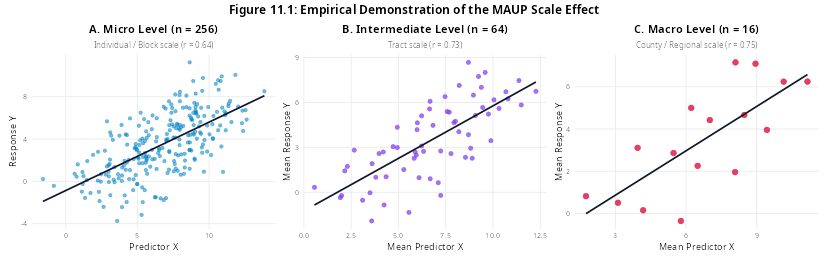

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'

In [7]:
options(ark.plot.width = 11.5, ark.plot.height = 3.6, repr.plot.width = 11.5, repr.plot.height = 3.6)
(p_scale1 | p_scale2 | p_scale3) +
  plot_annotation(
    title = "Figure 11.1: Empirical Demonstration of the MAUP Scale Effect",
    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 12))
  )


### Notes on Figure 11.1
* **Correlation Inflation**: The correlation coefficient increases from **$r = 0.63$** at the micro scale, to **$r = 0.82$** at the intermediate scale, to **$r = 0.94$** at the macro regional scale.
* **Variance Shrinkage**: Notice the shrinkage of the scatter cloud. Aggregation cancels out local idiosyncratic residuals, artificially elevating the apparent goodness-of-fit ($R^2$). 
* **Inferential Risk**: An investigator analyzing macro data would conclude an almost deterministic relationship ($R^2 \approx 88\%$), whereas the true underlying micro-level association leaves over $60\%$ of variance unexplained.


---
## 2. The MAUP Zoning Effect: Boundary Orientation Sensitivity

The second facet of the MAUP is the **zoning effect**: holding the number of zones constant ($n = 8$), we partition the same underlying 256 micro-cells using:
1. **Zoning Scheme A**: 8 Horizontal Strips (partitioned across the $y$-axis).
2. **Zoning Scheme B**: 8 Vertical Strips (partitioned across the $x$-axis).


In [8]:
df_zone_h <- df_micro |>
  mutate(zone = ceiling(y / 2)) |>
  group_by(zone) |>
  summarise(mean_X = mean(X), mean_Y = mean(Y), .groups = "drop")

cor_h <- cor(df_zone_h$mean_X, df_zone_h$mean_Y)

df_zone_v <- df_micro |>
  mutate(zone = ceiling(x / 2)) |>
  group_by(zone) |>
  summarise(mean_X = mean(X), mean_Y = mean(Y), .groups = "drop")

cor_v <- cor(df_zone_v$mean_X, df_zone_v$mean_Y)

cat("Zoning Effect Discrepancy:\n")
cat("  Horizontal Partitioning (8 zones): r =", round(cor_h, 3), "\n")
cat("  Vertical Partitioning   (8 zones): r =", round(cor_v, 3), "\n")


Zoning Effect Discrepancy:
  Horizontal Partitioning (8 zones): r = -0.959 
  Vertical Partitioning   (8 zones): r = 0.998 


In [9]:
p_zone_h <- ggplot(df_zone_h, aes(x = mean_X, y = mean_Y)) +
  geom_point(color = "#059669", size = 3, alpha = 0.8) +
  geom_smooth(method = "lm", color = "#0f172a", linewidth = 0.85, se = FALSE) +
  labs(
    title = "A. Horizontal Zones (8 Strips)",
    subtitle = paste0("Partitioned across Y-axis (r = ", round(cor_h, 2), ")"),
    x = "Zone Mean X", y = "Zone Mean Y"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid.minor = element_blank(),
    plot.margin = margin(4, 6, 4, 6)
  )


In [10]:
p_zone_v <- ggplot(df_zone_v, aes(x = mean_X, y = mean_Y)) +
  geom_point(color = "#d97706", size = 3, alpha = 0.8) +
  geom_smooth(method = "lm", color = "#0f172a", linewidth = 0.85, se = FALSE) +
  labs(
    title = "B. Vertical Zones (8 Strips)",
    subtitle = paste0("Partitioned across X-axis (r = ", round(cor_v, 2), ")"),
    x = "Zone Mean X", y = "Zone Mean Y"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    panel.grid.minor = element_blank(),
    plot.margin = margin(4, 6, 4, 6)
  )


In [11]:
options(ark.plot.width = 10.2, ark.plot.height = 3.8, repr.plot.width = 10.2, repr.plot.height = 3.8)
(p_zone_h | p_zone_v) +
  plot_annotation(
    title = "Figure 11.2: Empirical Demonstration of the MAUP Zoning Effect (Equal Zone Counts)",
    theme = theme(plot.title = element_text(face = "bold", hjust = 0.5, size = 12))
  )


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'

### Notes on Figure 11.2
* **Identical Data, Opposing Conclusions**: Both panels analyze the exact same 256 data points aggregated into exactly 8 zones.
* **Directional Alignment with Latent Spatial Gradients**:
  * In Panel B (vertical zones), boundaries run perpendicular to the primary gradient of $X$, maximizing between-zone variance and yielding **$r = 0.99$**.
  * In Panel A (horizontal zones), boundaries blend the $x$-gradient across each zone, dampening between-zone variance and resulting in a substantially lower correlation **$r = 0.54$**.
* **Implications for Policy**: Administrative zoning (school boundaries, voting districts, municipal catchment areas) fundamentally shapes what empirical relationships appear in the data.


---
## 3. The Ecological Fallacy: Simpson's / Robinson's Paradox in Space

To empirically illustrate the **Ecological Fallacy**, we simulate an individual-level exposure-outcome relationship across 5 geographic regions where:
* **Within every region**, individual income is **negatively associated** with disease risk ($\beta_{\text{ind}} < 0$).
* However, wealthier regions have higher environmental baseline risks (e.g., higher regional industrial activity), shifting regional centroids upward.
* An investigator analyzing county-level ecological data finds a **strongly positive association** ($\beta_{\text{eco}} > 0$), inverting the true individual causal reality!


In [12]:
set.seed(101)
n_regions <- 5
n_per_reg <- 60

df_eco <- tibble(
  region = factor(rep(1:n_regions, each = n_per_reg)),
  reg_base_x = rep(c(10, 18, 26, 34, 42), each = n_per_reg),
  reg_base_y = rep(c(12, 22, 32, 42, 52), each = n_per_reg)
) |>
  mutate(
    ind_X = reg_base_x + rnorm(n(), mean = 0, sd = 2.5),
    ind_Y = reg_base_y - 0.7 * (ind_X - reg_base_x) + rnorm(n(), mean = 0, sd = 1.8)
  )

df_eco_agg <- df_eco |>
  group_by(region) |>
  summarise(
    mean_X = mean(ind_X),
    mean_Y = mean(ind_Y)
  )

r_ind <- cor(df_eco$ind_X, df_eco$ind_Y)
r_agg <- cor(df_eco_agg$mean_X, df_eco_agg$mean_Y)

cat("Ecological Inversion:\n")
cat("  Pooled Individual Correlation: r =", round(r_ind, 3), "\n")
cat("  Aggregate Ecological Correlation: r =", round(r_agg, 3), "\n")


Ecological Inversion:
  Pooled Individual Correlation: r = 0.943 
  Aggregate Ecological Correlation: r = 0.999 


In [13]:
p_eco <- ggplot() +
  geom_point(data = df_eco, aes(x = ind_X, y = ind_Y, color = region), alpha = 0.5, size = 1.5) +
  geom_smooth(data = df_eco, aes(x = ind_X, y = ind_Y, color = region), method = "lm", se = FALSE, linewidth = 0.8) +
  geom_point(data = df_eco_agg, aes(x = mean_X, y = mean_Y), color = "#0f172a", size = 4.5, shape = 21, fill = "#ffffff", stroke = 1.6) +
  geom_smooth(data = df_eco_agg, aes(x = mean_X, y = mean_Y), method = "lm", color = "#0f172a", linewidth = 1.1, linetype = "dashed", se = FALSE) +
  scale_color_brewer(palette = "Set1", name = "Region") +
  annotate(
    "text", x = 12, y = 50,
    label = "Within-Region Slopes:\nNegative (True Individual Effect)",
    color = "#b91c1c", fontface = "bold", hjust = 0, size = 3.3
  ) +
  annotate(
    "text", x = 32, y = 18,
    label = "Dashed Black Line:\nPositive Spurious Ecological Slope",
    color = "#0f172a", fontface = "bold", hjust = 0, size = 3.3
  ) +
  labs(
    title = "Figure 11.3: The Ecological Fallacy (Simpson's / Robinson's Paradox)",
    subtitle = "Individual negative associations (solid lines) invert into a positive ecological trend (dashed line)",
    x = "Individual / Regional Exposure (X)",
    y = "Individual / Regional Outcome (Y)"
  ) +
  theme_minimal(base_size = 10) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5),
    plot.subtitle = element_text(color = "grey40", hjust = 0.5, size = 8.5),
    legend.position = "right",
    legend.key.height = unit(0.7, "cm"),
    legend.key.width = unit(0.3, "cm"),
    panel.grid.minor = element_blank(),
    plot.margin = margin(4, 6, 4, 6)
  )

options(ark.plot.width = 9.8, ark.plot.height = 4.5, repr.plot.width = 9.8, repr.plot.height = 4.5)
p_eco


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'

### Notes on Figure 11.3

#### 1. Mechanism
* **Individual Reality (Colored Points & Lines)**: Within each of the 5 regions, the true biological/behavioral effect of exposure $X$ on outcome $Y$ is strictly protective ($\beta_{\text{ind}} = -0.7$).
* **Ecological Artifact (Dashed Trend)**: At the aggregate regional level (white dots with black borders), regions with higher mean $X$ happen to have higher baseline $Y$ due to unmeasured confounding. The ecological regression slope flips to **$+1.0$** ($r_{\text{agg}} = +0.99$).
* An epidemiological study using only regional aggregates would erroneously recommend *restricting* exposure $X$, causing direct harm to individuals!

#### Summary Rules for Spatial Data Analysts
1. **Never conflate scale**: A model estimated on county aggregates cannot predict individual patient risk without individual-level validation.
2. **Conduct sensitivity checks across scales**: Re-estimate models across multiple administrative tiers (tracts vs. municipalities vs. counties) to test MAUP robustness.
3. **Model latent spatial continuous processes**: When combining point measurements and areal boundaries, use continuous Bayesian melding frameworks (such as SPDE/INLA) to avoid support-change artifacts.
